# 05 · Evaluation: the 2025 test, error analysis, calibration, limits
**Project:** Next-day PM2.5 exceedance alerts for Chennai · CS3006 · pipeline stage **7 Evaluate**

**How the test year was kept honest**
1. The model, its settings, training years and alert thresholds were fixed in stage 6 and saved in
   `reports/model_choice.json` (committed to the development repository before this notebook existed).
2. Every table and figure below was first built and checked on **2024 only**, and that code was
   committed before 2025 was loaded.
3. Then the same cells were run once with 2025 added. Nothing was changed afterwards because of
   what 2025 showed.

Nothing in this notebook chooses anything; it only measures.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # run from the notebooks/ folder

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C, evaluate as E, features as F, models as M, model_plots as MP
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
np.random.seed(C.RANDOM_SEED)

def show(fig_path):
    display(Image(str(fig_path)))

EVAL_YEARS = {2024: "val", 2025: "test"}     # 2026 stays untouched until stage 9
choice = M.load_choice()
assert choice["frozen_before_test"]
feats = F.make_features()
tr = F.model_rows(feats, "train")
rows = {yr: F.model_rows(feats, split) for yr, split in EVAL_YEARS.items()}
for yr, r in rows.items():
    assert set(r.target_date.dt.year) == {yr}
    print(f"{yr}: {len(r)} labelled station-days, {int(r.y.sum())} bad days, base rate {r.y.mean():.3f}")

2024: 902 labelled station-days, 76 bad days, base rate 0.084
2025: 1210 labelled station-days, 157 bad days, base rate 0.130


## 1 · The frozen methods
The primary model is refitted from the frozen settings on 2021-23. Logistic regression is
deterministic, so this is exactly the stage-6 model. The check below confirms it reproduces the
2024 numbers stored in the choice file.

In [2]:
primary, upper = E.frozen_models(tr, choice)
thr = E.thresholds(choice)
print("primary:", choice["primary"]["params"], "| alert if probability >=", round(thr["logreg"], 3))
print("reference: alert if today's PM2.5 >", round(choice["reference"]["threshold_ugm3"], 1), "µg/m³")
s24 = E.scores_for(rows[2024], primary)
stored = choice["validation_2024"]["logreg"]["PR-AUC"]
assert abs(M.average_precision_score(rows[2024].y, s24["logreg"]) - stored) < 1e-9, "not the frozen model!"
print("reproduces stored 2024 PR-AUC:", round(stored, 4))

primary: {'C_': 0.1, 'class_weight': None} | alert if probability >= 0.265
reference: alert if today's PM2.5 > 55.2 µg/m³
reproduces stored 2024 PR-AUC: 0.7049


## 2 · Headline results

In [3]:
scores = {yr: E.scores_for(r, primary) for yr, r in rows.items()}
heads = {yr: E.headline(rows[yr], scores[yr], thr) for yr in rows}
for yr, h in heads.items():
    print(f"\n=== {yr} ({'validation: thresholds were chosen here' if yr == 2024 else 'TEST'}) ===")
    display(h.drop(columns=["threshold"]))


=== 2024 (validation: thresholds were chosen here) ===


,base rate (no-skill PR-AUC),PR-AUC,ROC-AUC,Brier,alerts,caught,missed,false alarms,recall,precision,F1
model,,,,,,,,,,,
logreg,0.084,0.705,0.962,0.043,89,54,22,35,0.711,0.607,0.655
pm25_score,0.084,0.653,0.948,NaN,94,55,21,39,0.724,0.585,0.647
persistence,0.084,0.435,0.799,NaN,75,48,28,27,0.632,0.640,0.636
never,0.084,0.084,0.500,NaN,0,0,76,0,0.000,0.000,0.000



=== 2025 (TEST) ===


,base rate (no-skill PR-AUC),PR-AUC,ROC-AUC,Brier,alerts,caught,missed,false alarms,recall,precision,F1
model,,,,,,,,,,,
logreg,0.130,0.793,0.962,0.051,187,129,28,58,0.822,0.690,0.750
pm25_score,0.130,0.751,0.946,NaN,182,133,24,49,0.847,0.731,0.785
persistence,0.130,0.596,0.855,NaN,155,117,40,38,0.745,0.755,0.750
never,0.130,0.130,0.500,NaN,0,0,157,0,0.000,0.000,0.000



2024  (95% block-bootstrap intervals, 53 city-wide week blocks)


,PR-AUC (point),2.5%,97.5%
logreg,0.705,0.504,0.859
pm25_score,0.653,0.534,0.765
persistence,0.435,0.305,0.536
logreg - pm25_score,0.052,-0.080,0.158



2025  (95% block-bootstrap intervals, 53 city-wide week blocks)


,PR-AUC (point),2.5%,97.5%
logreg,0.793,0.688,0.875
pm25_score,0.751,0.587,0.887
persistence,0.596,0.444,0.711
logreg - pm25_score,0.042,-0.067,0.184


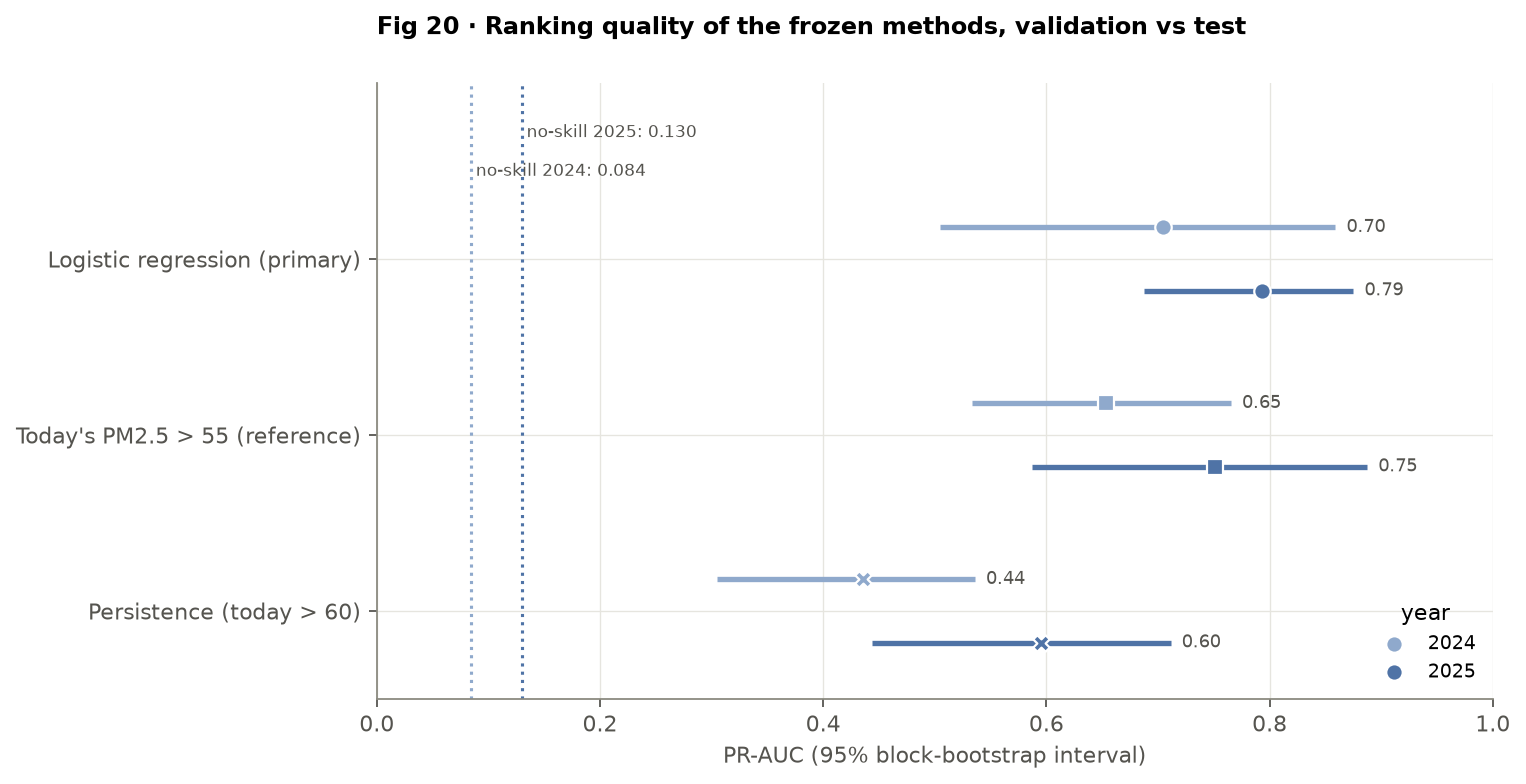

In [4]:
boot = {yr: M.block_bootstrap(rows[yr], {k: scores[yr][k] for k in ["logreg", "pm25_score", "persistence"]},
                              pairs=[("logreg", "pm25_score")]) for yr in rows}
for yr, b in boot.items():
    print(f"\n{yr}  (95% block-bootstrap intervals, {b.attrs['blocks']} city-wide week blocks)")
    display(b)
show(MP.fig_test_results(boot, {yr: rows[yr].y.mean() for yr in rows}, E.LABELS))

**What the test year says** (2024 is shown for comparison only: its thresholds were chosen on it,
so it flatters the methods)

* **Both frozen methods work on unseen data.** On 2025 the primary model catches **129 of 157** bad
  days (recall 0.82) and the "today > 55" rule catches **133** (0.85). Both are above the 0.7 target,
  and both are far above "never alert" and persistence (117 caught).
* **Ranking: the model is again ahead, again within noise.** PR-AUC is 0.79 vs 0.75. The difference
  of +0.04 has a 95% interval of −0.07 to +0.18, close to the +0.05 seen on 2024. The
  direction held up on a year the model never saw, but it is still not a clear win.
* **At the alert thresholds, the simple rule did better in 2025:** 4 more bad days caught and 9 fewer
  false alarms (precision 0.73 vs 0.69). The model ranks days slightly better overall, but at the
  one cut-off that matters for the public, the rule came out ahead this year.
* **Scores are higher than in 2024 partly because bad days were more common** (13.0% vs 8.4%).
  PR-AUC must be read against each year's no-skill level: 0.79 is 6.1× the 0.13 base rate in 2025,
  while 0.71 was 8.4× the 0.084 base rate in 2024. So relative to how easy each year was, the test
  year is *not* better than validation. The higher raw score mostly reflects more bad days.

**Conclusion for the viva:** a forecaster with *today's PM2.5 and a well-chosen cut-off* already
gets most of the achievable skill. The model's added value is small and uncertain, but its
probabilities and its better onset detection (§3) make it the more informative tool.

## 3 · Error analysis: which bad days are missed?
All error analysis uses the **primary model at its frozen threshold**.

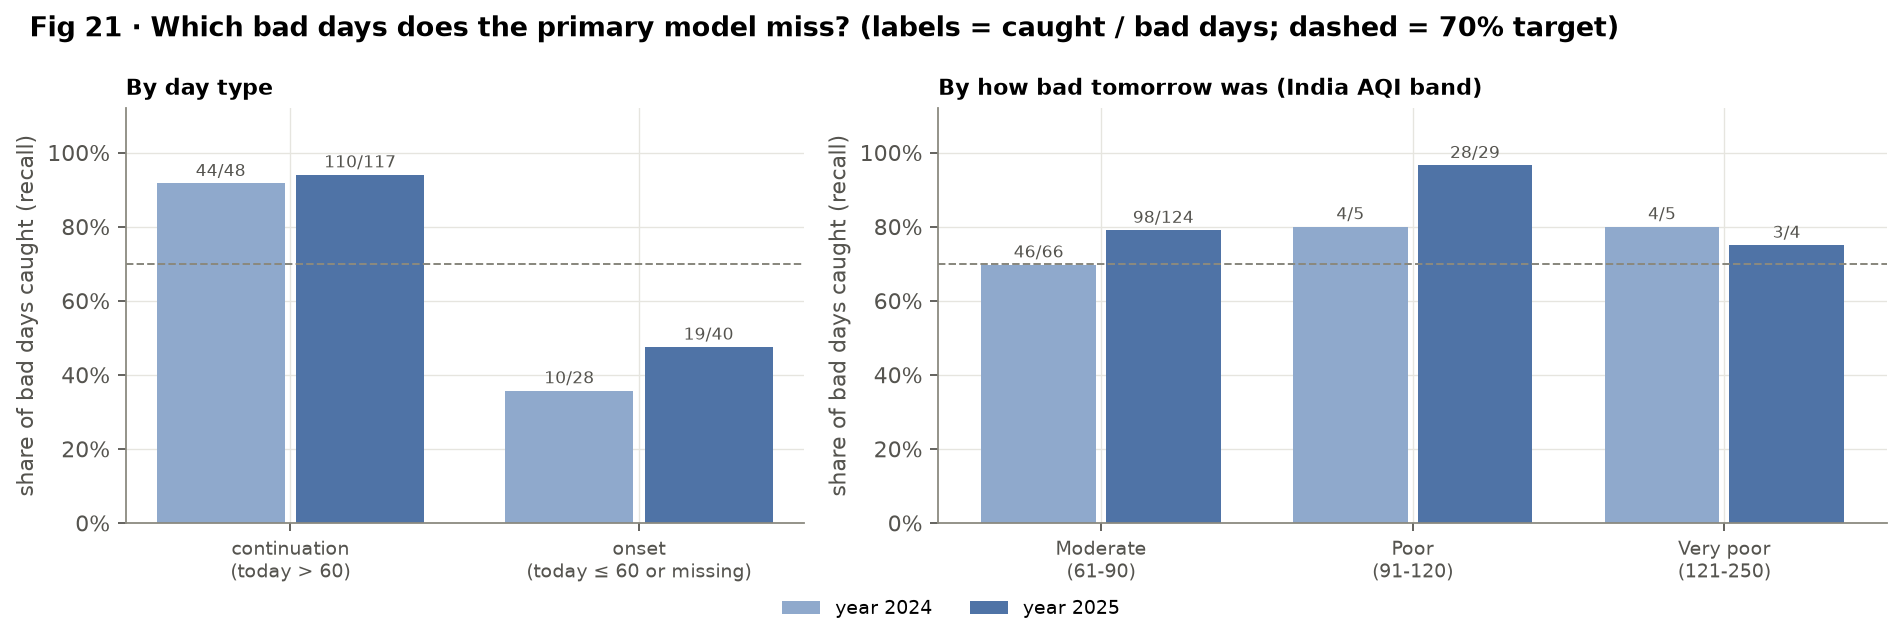


=== 2024 ===


,bad_days,caught,missed,recall
day type,,,,
continuation (today > 60),48,44,4,0.917
onset (today ≤ 60 or missing),28,10,18,0.357


,bad_days,caught,missed,recall
tomorrow band,,,,
Moderate (61-90),66,46,20,0.697
Poor (91-120),5,4,1,0.800
Very poor (121-250),5,4,1,0.800


,bad_days,caught,missed,recall
station,,,,
Arumbakkam,29,22,7,0.759
Manali,21,13,8,0.619
Perungudi,26,19,7,0.731


,bad_days,caught,missed,recall
festival tomorrow,,,,
False,70,48,22,0.686
True,6,6,0,1.000



=== 2025 ===


,bad_days,caught,missed,recall
day type,,,,
continuation (today > 60),117,110,7,0.940
onset (today ≤ 60 or missing),40,19,21,0.475


,bad_days,caught,missed,recall
tomorrow band,,,,
Moderate (61-90),124,98,26,0.790
Poor (91-120),29,28,1,0.966
Very poor (121-250),4,3,1,0.750


,bad_days,caught,missed,recall
station,,,,
Arumbakkam,52,40,12,0.769
Kodungaiyur,35,33,2,0.943
Manali,15,14,1,0.933
Perungudi,55,42,13,0.764


,bad_days,caught,missed,recall
festival tomorrow,,,,
False,154,126,28,0.818
True,3,3,0,1.000


In [5]:
alerts = {yr: E.alerts_frame(rows[yr], scores[yr], thr) for yr in rows}
recall_tables = {yr: {k: E.recall_by(alerts[yr], k) for k in ["day type", "tomorrow band"]} for yr in rows}
show(MP.fig_missed(recall_tables))
for yr in rows:
    print(f"\n=== {yr} ===")
    for col in ["day type", "tomorrow band", "station", "festival tomorrow"]:
        display(E.recall_by(alerts[yr], col))

In [6]:
for yr in rows:
    print(f"{yr}: false alarms by what tomorrow actually was")
    display(E.false_alarm_profile(alerts[yr]))

2024: false alarms by what tomorrow actually was


,false alarms,share
pm25_next,,
< 30 (clean),5,0.143
30-45,11,0.314
45-60 (near miss),19,0.543


2025: false alarms by what tomorrow actually was


,false alarms,share
pm25_next,,
< 30 (clean),7,0.121
30-45,12,0.207
45-60 (near miss),39,0.672


**Where the misses are (2025, primary model)**
* **Onset days are the weak spot, as predicted in stage 4.** When a bad spell is already under way,
  the model catches **110 of 117** (94%). When today is fine and tomorrow turns bad, it catches
  **19 of 40** (48%). That is better than 2024's 36%, but these are still the days persistence can
  never catch and where most misses come from (21 of 28).
* **The worse the day, the more likely it is caught.** 79% of *Moderate* days (61-90) were caught,
  97% of *Poor* days (91-120, 28 of 29), and 3 of 4 *Very poor* days. Most misses are days just over
  the limit.
* **Stations.** Kodungaiyur (back in the data after its 2025 repair) and Manali, the two northern
  industrial sites, have the *highest* recall (94% and 93%). Arumbakkam and Perungudi are about 77%.
  So the fear that the most exposed areas get the least warning is **not** borne out in 2025,
  although the counts are small (15-55 bad days per station).
* **Festivals:** 3 of 3 festival-day exceedances were caught (and 6 of 6 in 2024).
* **False alarms are mostly near misses:** 39 of 58 (67%) were days at 45-60 µg/m³, just under the
  limit. Only 7 were genuinely clean days (< 30). For a health advisory, a near miss is a much
  cheaper error than it looks.

### Day by day: October-December of the latest evaluated year

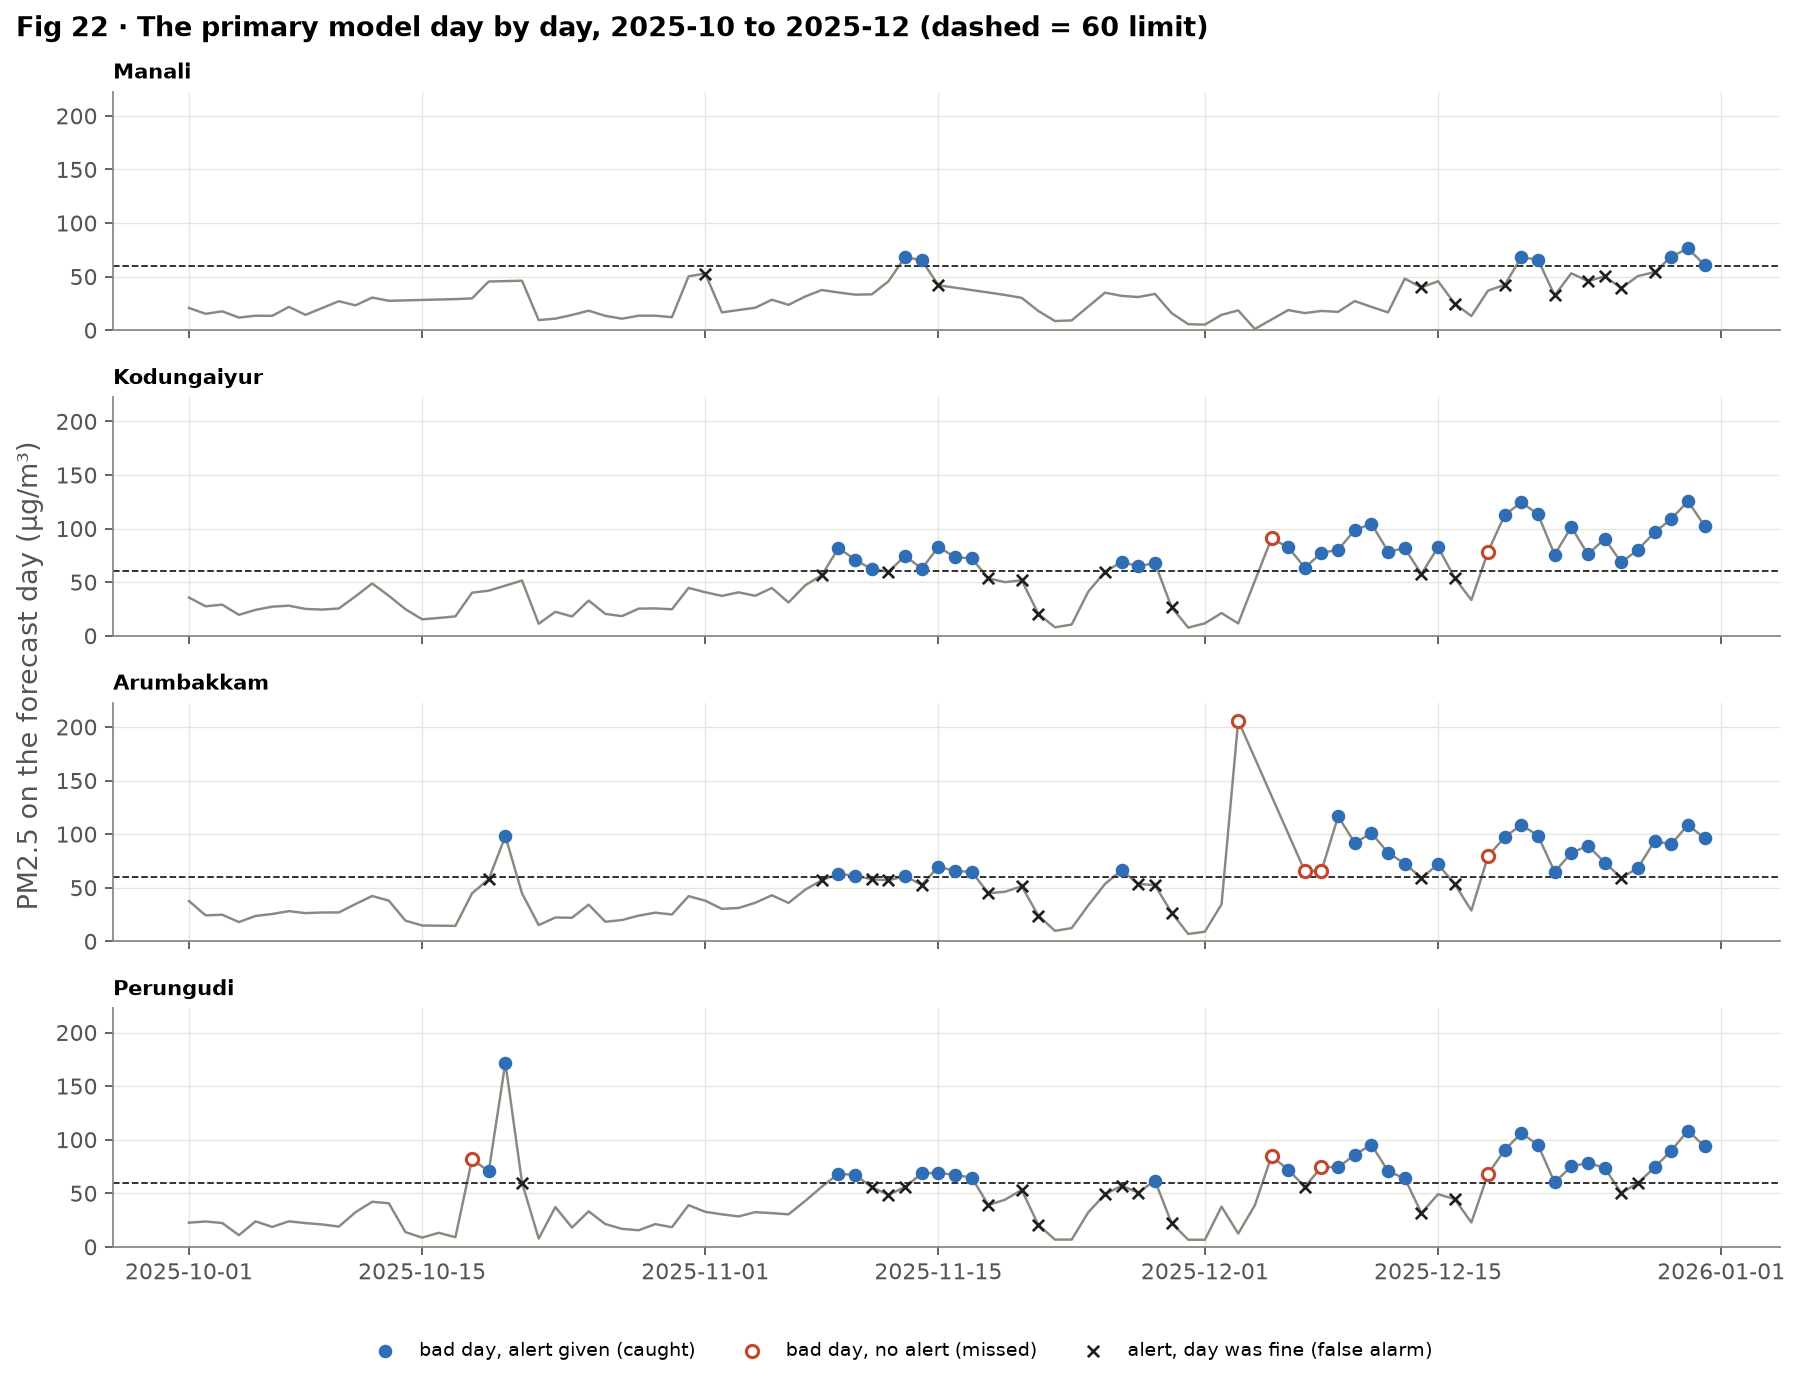

In [7]:
yr = max(rows)
a = alerts[yr]
window = a[a.target_date.between(f"{yr}-10-01", f"{yr}-12-31")]
stations = [s for s in ["Manali", "Kodungaiyur", "Arumbakkam", "Perungudi"]
            if window[window.station == s].y.notna().sum() >= 30]
show(MP.fig_timeline(a, f"{yr}-10-01", f"{yr}-12-31", stations))

The timeline shows the pattern from the tables:
* **Runs of bad days are caught almost entirely, and the misses (open red circles) fall on the
  first day of a run:** e.g. 5 Dec and 18 Dec at several stations.
* **The largest single miss** is Arumbakkam jumping from 35 to **206 µg/m³ on 3 Dec 2025**.
  Nothing in that day's data hinted at it. No day-ahead method using today's data could have
  caught it. (Its sensor then reports nothing for 4-6 Dec; the line joins across that gap.)
* **False alarms (×)** come on the day *after* a run ends (the air has cleared but today's reading
  is still high), and in spells that hover just under 60 (mid-November).
* **Diwali (20 Oct 2025):** the spikes at Perungudi (171) and Arumbakkam (98) were both caught.
  Perungudi's pre-Diwali exceedance on 18 Oct was missed.

## 4 · Calibration: can the probabilities be trusted?
If the model says 30%, about 30% of such days should turn out bad. The model learned from
training years where 6.1% of days were bad.

The "corrected" curve is an **after-the-fact what-if**: it shifts the model's log-odds by the change
in the base rate (a standard *prior-shift* correction), *as if* the new year's base rate were known
in advance. It is not part of the test result. It shows what a recalibration step could do.

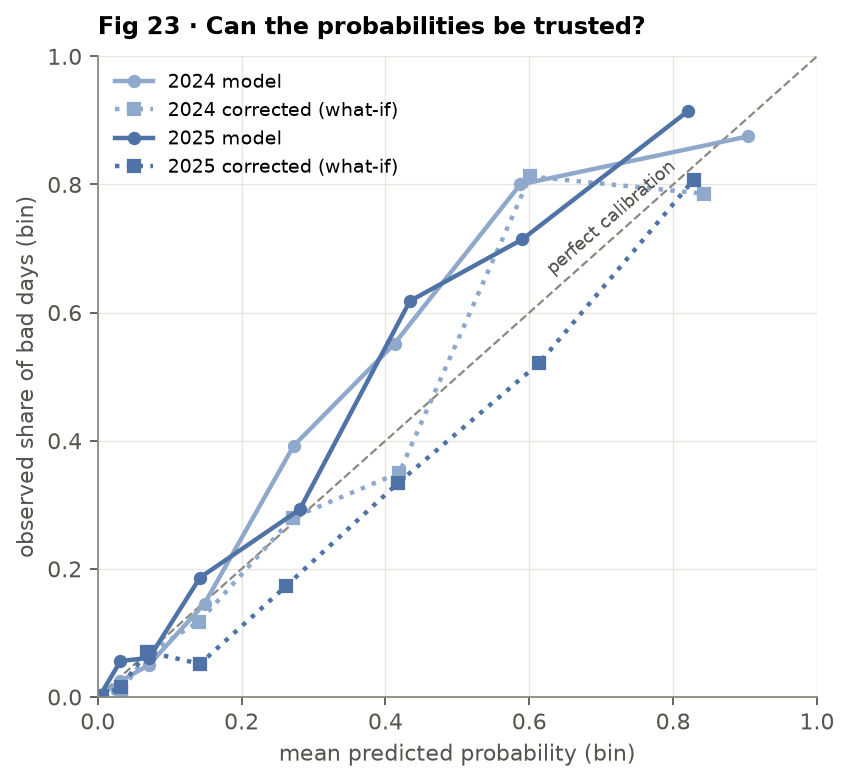

,actual base rate,mean predicted probability,Brier (model),"Brier (corrected, what-if)"
year,,,,
2024,0.084,0.071,0.043,0.041
2025,0.130,0.107,0.051,0.050


2024 model


,rows,mean_predicted,observed_rate
bin,,,
"(-0.001, 0.02]",599,0.003,0.002
"(0.02, 0.05]",82,0.031,0.024
"(0.05, 0.1]",60,0.071,0.050
"(0.1, 0.2]",48,0.148,0.146
"(0.2, 0.35]",51,0.272,0.392
"(0.35, 0.5]",29,0.413,0.552
"(0.5, 0.7]",25,0.587,0.800
"(0.7, 1.0]",8,0.904,0.875


2025 model


,rows,mean_predicted,observed_rate
bin,,,
"(-0.001, 0.02]",789,0.004,0.004
"(0.02, 0.05]",107,0.032,0.056
"(0.05, 0.1]",49,0.072,0.061
"(0.1, 0.2]",59,0.142,0.186
"(0.2, 0.35]",41,0.281,0.293
"(0.35, 0.5]",55,0.434,0.618
"(0.5, 0.7]",63,0.590,0.714
"(0.7, 1.0]",47,0.821,0.915


In [8]:
rel, summary = {}, []
for yr in rows:
    y, p = rows[yr].y.to_numpy(), scores[yr]["logreg"]
    pc = E.prior_shift(p, tr.y.mean(), y.mean())
    rel[f"{yr} model"] = E.reliability(y, p)
    rel[f"{yr} corrected (what-if)"] = E.reliability(y, pc)
    summary.append({"year": yr, "actual base rate": y.mean(), "mean predicted probability": p.mean(),
                    "Brier (model)": M.brier_score_loss(y, p),
                    "Brier (corrected, what-if)": M.brier_score_loss(y, pc)})
show(MP.fig_reliability(rel))
display(pd.DataFrame(summary).set_index("year"))
for name, t in rel.items():
    if "model" in name:
        print(name); display(t)

**The probabilities are too low, and more so as the base rate rises.** In 2025 the model's average
probability was 0.107 against an actual rate of 0.130. In the 35-50% bin, 62% of days were really
bad. This is the base-rate shift from notebook 02 §9: the model learned from years with 6% bad days.

* **It is not only drift.** In 2024 too, the curve sits *above* the diagonal in the middle range
  (predicted ~0.27 → observed 0.39). So the model is under-confident even before the base rate moves.
  A likely reason is the L2 penalty chosen in stage 6 (C = 0.1): it shrinks the weights, which pulls
  every probability towards the average. That shrinkage helped ranking, but costs calibration.
* It **does not break the alerts**, because the alert uses a fixed probability cut-off, and the
  model still ranks bad days high (2025 recall 0.82).
* The **prior-shift what-if over-corrects in 2025:** its dotted curve falls *below* the diagonal.
  It moves every probability up by the same amount, but the low bins were already about right and
  only the middle bins were too low. The Brier score barely changes (0.051 → 0.050). A proper
  recalibration (e.g. Platt scaling fitted on the most recent year, §6) is needed, not a shift.
* **Practical meaning:** a probability shown to the public, such as "40% chance tomorrow is unsafe",
  would understate the risk. Use the yes/no alert, or recalibrate first.

## 5 · Upper bound: what would a perfect weather forecast add?
Same model and settings, plus tomorrow's **actual** weather (`F.NEXT_DAY_FEATURES`), trained on
2021-23. A real forecast has errors, so this is the most that better weather information could add.
It is an experiment, not a result: the system cannot know tomorrow's weather at the end of today.
Compared by PR-AUC only, so nothing is tuned on the year being scored.

2024


,PR-AUC (point),2.5%,97.5%
logreg,0.705,0.504,0.859
with D+1 weather,0.723,0.599,0.853
with D+1 weather - logreg,0.018,-0.061,0.105


2025


,PR-AUC (point),2.5%,97.5%
logreg,0.793,0.688,0.875
with D+1 weather,0.833,0.733,0.895
with D+1 weather - logreg,0.040,-0.008,0.077


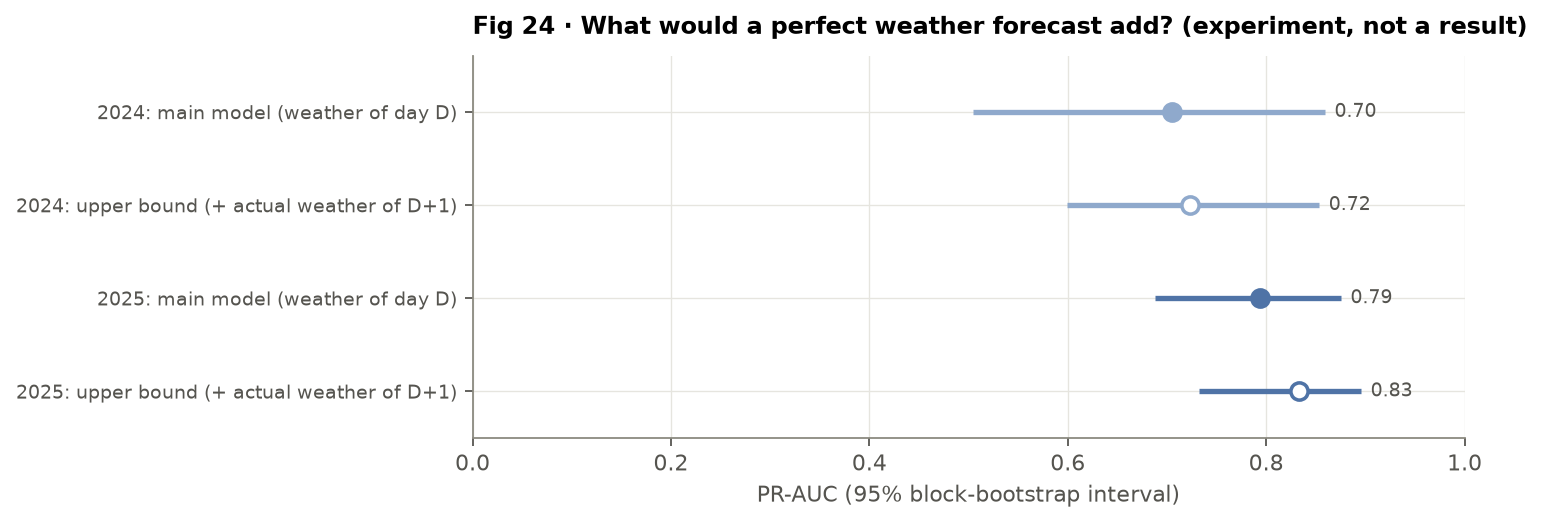

In [9]:
ub = {yr: M.block_bootstrap(rows[yr], E.upper_bound(rows[yr], primary, upper),
                            pairs=[("with D+1 weather", "logreg")]) for yr in rows}
for yr, t in ub.items():
    print(yr); display(t)
show(MP.fig_upper_bound(ub))

**Even a perfect weather forecast adds little, and not clearly.** With tomorrow's *actual* weather,
PR-AUC rises from 0.79 to 0.83 in 2025 (+0.04, interval −0.01 to +0.08) and from 0.71 to 0.72 in 2024
(+0.02, interval −0.06 to +0.11). Both intervals include 0. Real forecasts have errors, so the
realistic gain is smaller still.

**Meaning:** most of what can be known about tomorrow's PM2.5 at the end of today is already
in today's PM2.5. Weather forecasts are the next thing worth adding, but they will not transform
the system.

## 6 · Limitations, bias and next steps

**Data**
* **Four stations for a city of ~10 million.** They sit near roads and industry, so they do not
  represent every neighbourhood, and the stations that were excluded (Velachery, Royapuram, Alandur,
  Ennore) cover other parts of the city.
* **Kodungaiyur is missing for almost three years** (drift exclusion), so the model knows least
  about one of the two industrial northern stations, where exposure is highest.
* **Cleaning decisions shape the labels.** Removing 14.7% of PM2.5 days as sensor faults was
  documented and backed by two signals, but a wrongly removed bad day is a missing positive.
* **Cleaning was done once, with hindsight.** Two rules look a few days ahead (the flatline rule
  uses a centred 14-day window; the stuck-value rule needs later days to confirm a run), and the
  drift exclusions were decided by viewing all years, including 2025 (e.g. Kodungaiyur's exclusion
  ends at its March 2025 repair). A live system would only see the past. We checked the size of
  this: with strictly backward-looking rules, 3 of 6,833 PM2.5 values change and the 2025 results
  are identical. The drift decisions are data-quality judgements, not model tuning.
* **Weather is reanalysis (ERA5), not a forecast or a station measurement.** It is smooth on a
  ~10 km grid and may miss very local conditions.

**Statistics**
* **Few bad days:** 67-76 per validation year. Every comparison has wide intervals, and model
  differences of ±0.05 PR-AUC cannot be told apart from luck.
* **Correlated days and stations:** neighbouring days are near-copies and the four stations move
  together, so intervals resample whole city-wide weeks and tuning uses forward-chaining CV. The
  simple tests in notebook 02 correct only for day-to-day correlation, so they still overstate
  certainty somewhat (their conclusions hold by a wide margin).
* **Sub-group results** (onset vs continuation, station, AQI band) rest on small counts.

**Drift and fairness**
* **The base rate doubled** (6% in training → about 13% in 2025-26). A model trained on the past
  under-predicts the probability, and a fixed threshold's alert rate changes with it.
* **Who bears the errors?** Recall differs by station (§3). If the northern industrial stations are
  missed more often, the people most exposed get the least warning. With these counts we can flag
  it, not prove it.

**Next steps**
1. **Use real weather forecasts** (e.g. IMD or Open-Meteo forecast archives) instead of day-D
   reanalysis, for a fair version of the upper bound in §5.
2. **Hourly data:** an evening reading (6-9 pm) may predict the next day better than the daily mean.
3. **Recalibrate yearly** (prior-shift or Platt scaling on the latest year) and review the threshold
   each season.
4. **More stations** across Chennai, with a spatial feature.
5. **Monitoring** (stage 9): track recall and the alert rate month by month in 2026.

## 7 · Summary

| Question | Answer (2025 test, frozen methods) |
|---|---|
| Does the system meet the 70% recall target on unseen data? | **Yes:** model 82%, simple rule 85% |
| Does the model beat "today's PM2.5"? | Ranks slightly better (PR-AUC 0.79 vs 0.75), **not clearly**; at the alert threshold the rule did slightly better |
| Which bad days are missed? | Onset days (52% missed) and days just over the limit; 97% of *Poor* days caught |
| Are false alarms costly? | Mostly not: 67% were days at 45-60 µg/m³ |
| Can the probabilities be trusted? | Not as stated: too low in the middle range (L2 shrinkage, worsened by the base-rate rise); recalibrate before showing them |
| Would better weather help? | A little at most (+0.04 PR-AUC even with perfect weather; not clear) |

**Next:** stage 8 (Deploy) packages the frozen method as a daily script that reads today's data and
prints tomorrow's alert per station. Stage 9 (Monitor) runs it over 2026 and tracks recall and the
alert rate month by month.